In [3]:
import pandas as pd

F_100 = pd.read_csv("/Users/aditiiyer/Documents/Thesis/test_set_predictions_model_F_100.csv")
F_n_75 = pd.read_csv("/Users/aditiiyer/Documents/Thesis/test_set_predictions_model_F_n_75.csv")
Rs_100 = pd.read_csv("/Users/aditiiyer/Documents/Thesis/test_set_predictions_model_Rs_100.csv")
Rs_n_75 = pd.read_csv("/Users/aditiiyer/Documents/Thesis/test_set_predictions_model_Rs_n_75.csv")

In [9]:
import pandas as pd

F_100 = pd.read_csv("/Users/aditiiyer/Documents/Thesis/test_set_predictions_model_F_100.csv")
F_n_75 = pd.read_csv("/Users/aditiiyer/Documents/Thesis/test_set_predictions_model_F_n_75.csv")
Rs_100 = pd.read_csv("/Users/aditiiyer/Documents/Thesis/test_set_predictions_model_Rs_100.csv")
Rs_n_75 = pd.read_csv("/Users/aditiiyer/Documents/Thesis/test_set_predictions_model_Rs_n_75.csv")

F_100["Model"] = "F_100"
F_n_75["Model"] = "F_n_75"
Rs_100["Model"] = "Rs_100"
Rs_n_75["Model"] = "Rs_n_75"

combined_df = pd.concat(
    [F_100, F_n_75, Rs_100, Rs_n_75],
    ignore_index=True
)
combined_df.head()

,latitude,longitude,Observed_TOC,Predicted_TOC,Error,Absolute_Error,Model,lat,lon
0,33.33582,78.03325,5.284,8.458232,-3.174232,3.174232,F_100,NaN,NaN
1,33.36280,78.01393,10.990,11.405382,-0.415382,0.415382,F_100,NaN,NaN
2,33.36178,78.01774,10.540,6.933662,3.606338,3.606338,F_100,NaN,NaN
3,33.33551,78.03239,1.336,10.272639,-8.936639,8.936639,F_100,NaN,NaN
4,33.36710,78.01224,1.115,13.286214,-12.171214,12.171214,F_100,NaN,NaN


In [11]:
import numpy as np

combined_df = combined_df.rename(columns={"model": "Model"})

combined_df["Error_Sign"] = np.where(
    combined_df["Error"] >= 0,
    "Underprediction",
    "Overprediction"
)

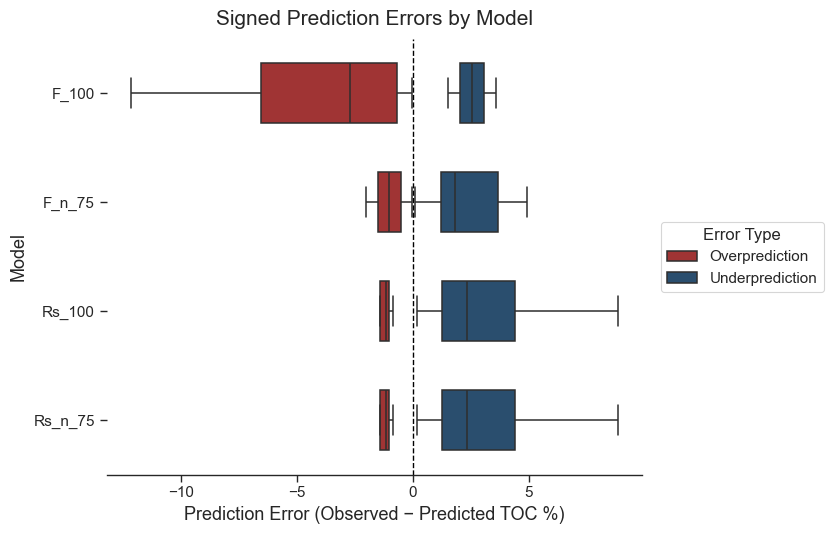

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(
    style="ticks",
    context="paper",
    font_scale=1.25
)

palette = {
    "Overprediction": "#b22222",
    "Underprediction": "#1f4e79"
}

fig, ax = plt.subplots(figsize=(8.5, 5.5))

sns.boxplot(
    data=combined_df,
    y="Model",
    x="Error",
    hue="Error_Sign",
    palette=palette,
    width=0.55,
    linewidth=1.1,
    dodge=False,
    showfliers=False,
    ax=ax
)

ax.axvline(
    0,
    linestyle="--",
    color="black",
    linewidth=1
)

ax.set_title(
    "Signed Prediction Errors by Model",
    fontsize=15,
    pad=10
)

ax.set_xlabel(
    "Prediction Error (Observed − Predicted TOC %)",
    fontsize=13
)

ax.set_ylabel(
    "Model",
    fontsize=13
)

sns.despine(left=True)

ax.legend(
    title="Error Type",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=True
)

plt.subplots_adjust(right=0.78)
plt.tight_layout()
plt.show()

In [13]:
r2_map = {
    "F_100": -0.26,
    "F_n_75": 0.017,
    "Rs_100": -0.86,
    "Rs_n_75": 0.36
}

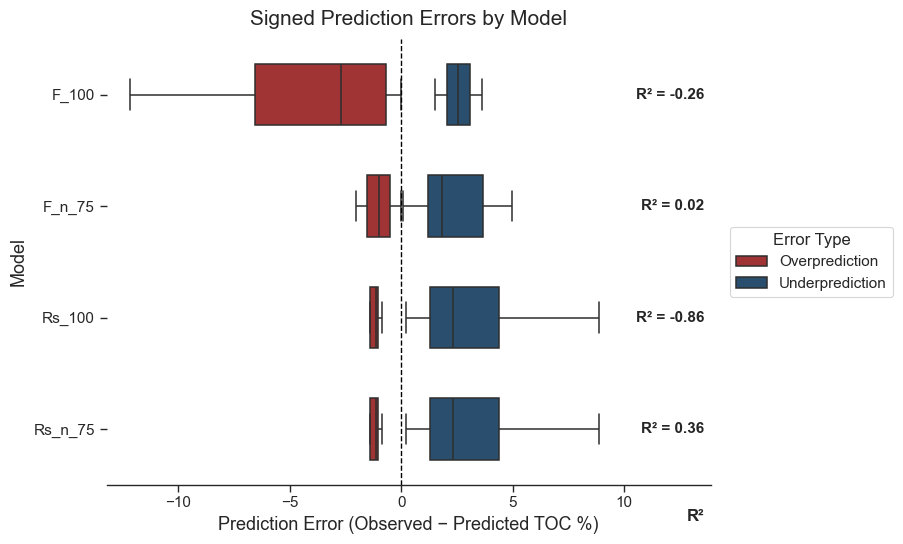

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(
    style="ticks",
    context="paper",
    font_scale=1.25
)

palette = {
    "Overprediction": "#b22222",
    "Underprediction": "#1f4e79"
}

fig, ax = plt.subplots(figsize=(9.2, 5.6))

sns.boxplot(
    data=combined_df,
    y="Model",
    x="Error",
    hue="Error_Sign",
    palette=palette,
    width=0.55,
    linewidth=1.1,
    dodge=False,
    showfliers=False,
    ax=ax
)

ax.axvline(
    0,
    linestyle="--",
    color="black",
    linewidth=1
)

ax.set_title(
    "Signed Prediction Errors by Model",
    fontsize=15,
    pad=10
)

ax.set_xlabel(
    "Prediction Error (Observed − Predicted TOC %)",
    fontsize=13
)

ax.set_ylabel(
    "Model",
    fontsize=13
)

sns.despine(left=True)

ax.legend(
    title="Error Type",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=True
)

xmin, xmax = ax.get_xlim()
ax.set_xlim(xmin, xmax * 1.4)

x_text = ax.get_xlim()[1] * 0.98

for i, label in enumerate(ax.get_yticklabels()):
    model_name = label.get_text()
    if model_name in r2_map:
        ax.text(
            x_text,
            i,
            f"R² = {r2_map[model_name]:.2f}",
            ha="right",
            va="center",
            fontsize=11,
            fontweight="bold"
        )

ax.text(
    x_text,
    len(ax.get_yticklabels()) - 0.15,
    "R²",
    ha="right",
    va="bottom",
    fontsize=12,
    fontweight="bold"
)

plt.subplots_adjust(right=0.83)
plt.tight_layout()
plt.show()